# Covariate groups

Forecasting models that take covariates must learn which inputs carry information, at which lag, and whether a covariate is known for the forecast periods. `GroupPrior` samples *groups* of aligned channels for exactly that: every channel is a target or a covariate, every covariate is either known in the future (`"future"`) or observed only up to the forecast origin (`"past"`), and the ground truth of each group comes back as a recipe.

::: {.callout-note}
## Four mechanisms

- **`RegressionSpec`**: one target caused by sampled covariates through a random structural regression (lags, nonlinear edges, interactions, distributed lags), plus distractors drawn from the same generator pool.
- **`FixedRegressionSpec`**: an explicit regression, used by the covariate-extraction probes.
- **`CoupledSpec`**: related channels from one base generator, coupled by mixing and lead-lag (a Chronos-2-style multivariatizer).
- **`VARXSpec`**: a linear VAR panel of targets driven by regressors, with an oracle forecast.
:::

Everything is causal: a discarded burn-in window absorbs lags and filters and fixes all scaling, so no future value shapes the past.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from synforecast import (
    CoupledSpec,
    GeneratorSpec,
    GroupPrior,
    RegressionSpec,
    VARXSpec,
    VARXTruth,
    probe_suite,
)
from synforecast.generators import TSIGenerator


## A covariate regression prior

The default `RegressionSpec` draws one to six covariates per group, one to three of them informative, and makes 15% of groups null (every covariate a distractor). `p_known_future` sets the share of covariates known for the forecast periods, independently of informativeness, and channels are shuffled, so neither role nor position gives the answer away.


In [ ]:
prior = GroupPrior(
    mechanism=RegressionSpec(p_known_future=0.5),
    length=(256, 256),
    freq="D",
)
batch = prior.sample(n_groups=8, seed=0)
print(batch.diagnostics)
df = batch.to_long(engine="polars")
df.head()


{'n_groups': 8, 'n_null': 0, 'n_redrawn': 0, 'n_fallback': 0, 'n_generator_fallback': 0, 'n_controls': 0}


group_id,unique_id,ds,y,role
i64,str,datetime[ns],f64,str
0,"""0_0""",2000-01-01 00:00:00,-0.671502,"""past"""
0,"""0_0""",2000-01-02 00:00:00,0.709447,"""past"""
0,"""0_0""",2000-01-03 00:00:00,0.513848,"""past"""
0,"""0_0""",2000-01-04 00:00:00,0.457897,"""past"""
0,"""0_0""",2000-01-05 00:00:00,1.290752,"""past"""


## Inspect the ground truth

The recipe lists every channel (target first) with its role, whether it is informative, its generator and seed, and every term (kind, driver, coefficient, lag), plus the composition and the calibrated effect strength. `GroupPrior.replay(recipe)` rebuilds the group exactly, and `draw_channel` redraws any latent channel from its spec and seed.


In [ ]:
group = next(g for g in batch if not g.recipe["null"])
for ch in group.recipe["channels"][1:]:
    kind = "informative" if ch["informative"] else "distractor"
    print(ch["channel"], ch["role"], kind, ch["spec"]["generator"].rsplit(".", 1)[-1])
group.recipe["terms"], group.recipe["composition"], round(group.recipe["realized"], 3)


5 past informative SARIMAGenerator
0 past informative SARIMAGenerator
6 past distractor SARIMAGenerator
2 past distractor OrnsteinUhlenbeckGenerator
3 past distractor PoissonProcessGenerator
1 future distractor TSIGenerator


([{'kind': 'hinge',
   'driver': 1,
   'partner': None,
   'lag': 0,
   'partner_lag': 0,
   'coef': 0.8353122073468151,
   'param': -0.1546255576046831,
   'adstock': None,
   'driver_channel': 5,
   'partner_channel': None},
  {'kind': 'signed_sqrt',
   'driver': 2,
   'partner': None,
   'lag': 6,
   'partner_lag': 0,
   'coef': 0.9986049678946055,
   'param': None,
   'adstock': None,
   'driver_channel': 0,
   'partner_channel': None}],
 'additive',
 0.013)

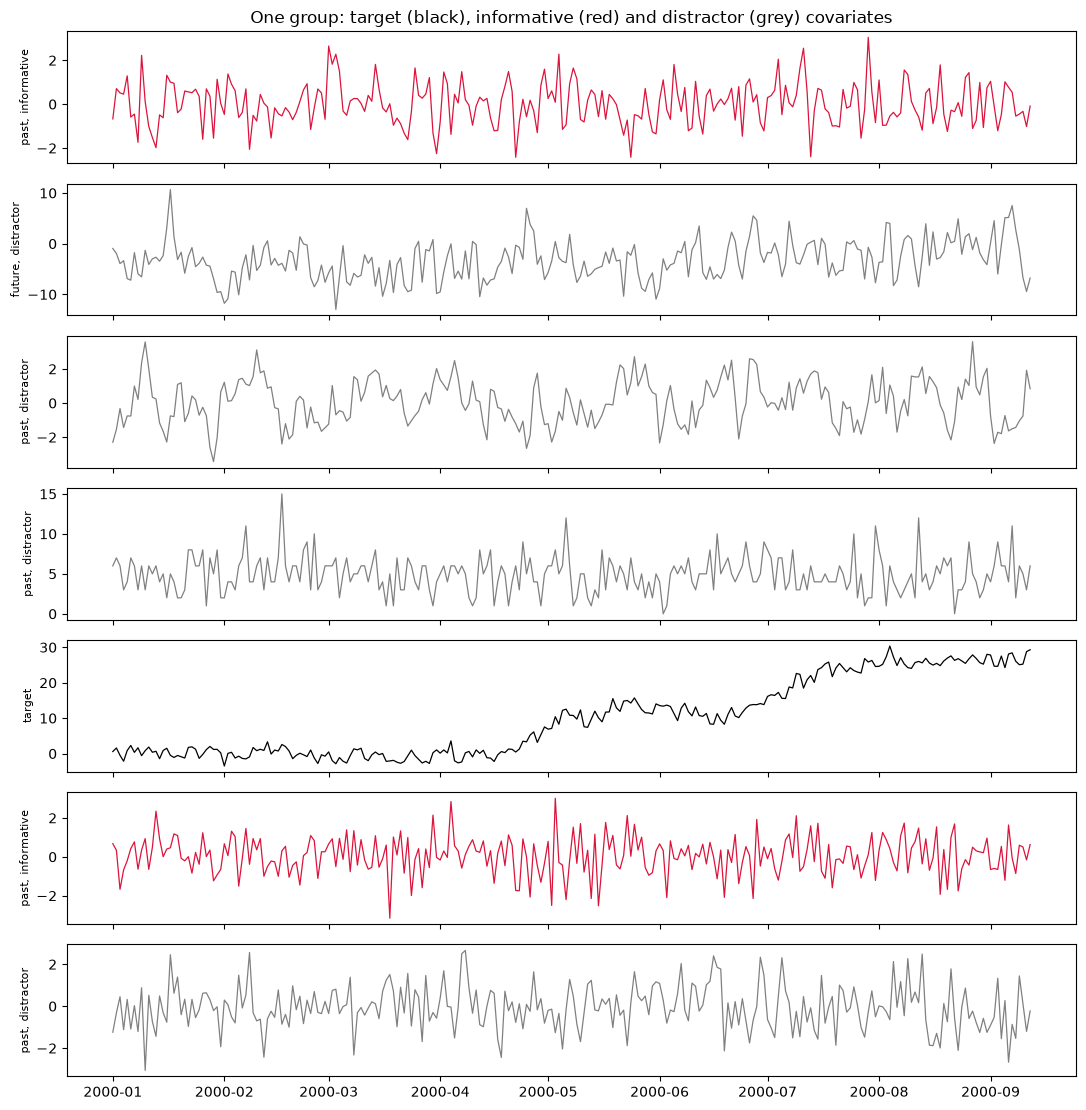

In [ ]:
informative = {c["channel"] for c in group.recipe["channels"][1:] if c["informative"]}
fig, axes = plt.subplots(len(group.roles), 1, figsize=(11, 1.6 * len(group.roles)), sharex=True)
for channel, (ax, role) in enumerate(zip(axes, group.roles, strict=True)):
    color = "black" if role == "target" else ("crimson" if channel in informative else "grey")
    label = role if role == "target" else f"{role}, {'informative' if channel in informative else 'distractor'}"
    ax.plot(group.timestamps, group.values[channel], color=color, linewidth=0.9)
    ax.set_ylabel(label, fontsize=8)
axes[0].set_title("One group: target (black), informative (red) and distractor (grey) covariates")
plt.tight_layout()
plt.show()


## Coupled channels

`CoupledSpec` turns one base generator into cross-dependent channels: `mixing` blends channels instantaneously, `leadlag` makes a channel a lagged, noisy copy of an earlier one. Lags read the burn-in, so nothing wraps around the end of the series. With `targets="all"` every channel is a target; with `targets="one"` one channel is the target and the rest are covariates.


In [ ]:
tsi = GeneratorSpec(generator=TSIGenerator)
coupled = GroupPrior(mechanism=CoupledSpec(base_pool=[tsi], n_channels=(4, 4)), length=(256, 256), freq="h", burn_in=96)
panel = coupled.sample(n_groups=1, seed=42)[0]
panel.recipe["coupling"]["leadlag"]


[{'src': 0, 'dst': 1, 'lag': 17, 'sign': 1.0, 'noise': 0.10400978067086616}]

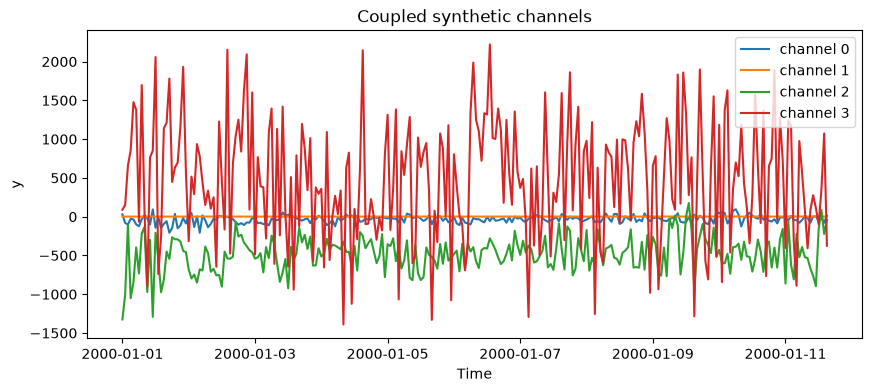

array([[ 1.  ,  0.21, -0.11, -0.08],
       [ 0.21,  1.  ,  0.03, -0.13],
       [-0.11,  0.03,  1.  ,  0.2 ],
       [-0.08, -0.13,  0.2 ,  1.  ]])

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for channel in range(panel.values.shape[0]):
    ax.plot(panel.timestamps, panel.values[channel], label=f"channel {channel}")
ax.set(title="Coupled synthetic channels", xlabel="Time", ylabel="y")
ax.legend()
plt.show()
np.corrcoef(panel.values).round(2)


## A VARX panel with an oracle

`VARXSpec` simulates several targets that depend on each other's lags and on shared, future-known and past-only regressors with known effects. `VARXTruth.from_recipe` rebuilds the process, and `forecast_group` returns its conditional-mean forecast, an oracle for excess-loss comparisons.


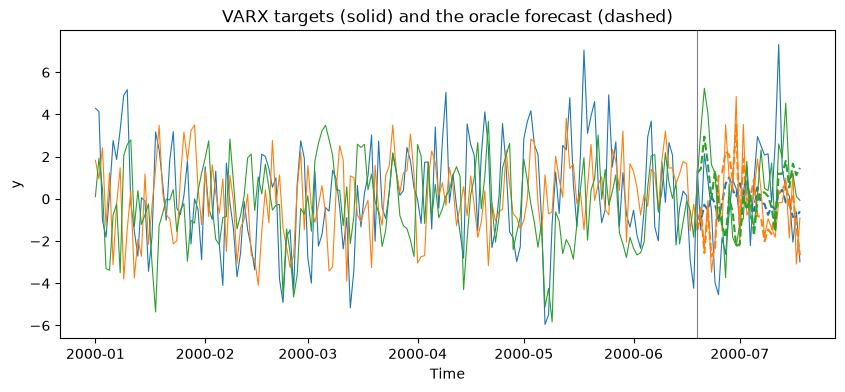

In [ ]:
varx = GroupPrior(
    mechanism=VARXSpec(n_targets=(3, 3), n_shared=1, n_future=1, n_past=1, exog_cross_scale=0.3),
    length=(200, 200),
    freq="D",
    burn_in=100,
)
group = varx.sample(n_groups=1, seed=1)[0]
truth = VARXTruth.from_recipe(group.recipe)
parts = VARXTruth.split(group)
origin, h = 170, 30
oracle = truth.forecast_group(group, origin=origin, h=h)

fig, ax = plt.subplots(figsize=(10, 4))
for i in range(parts["y"].shape[1]):
    line, = ax.plot(group.timestamps, parts["y"][:, i], linewidth=0.8)
    ax.plot(group.timestamps[origin:origin + h], oracle[:, i], "--", color=line.get_color())
ax.axvline(group.timestamps[origin], color="grey", linewidth=0.8)
ax.set(title="VARX targets (solid) and the oracle forecast (dashed)", xlabel="Time", ylabel="y")
plt.show()


## Covariate-extraction probes

`probe_suite()` returns fixed tasks in the style of the controlled covariate study in arXiv:2605.12200: identity, sum, nonlinear and quadratic relations, with target autoregression, known-future or past-only covariates, distractors, and IID or smooth drivers. Pair each probe with `shuffle_covariates`, which gives every target another group's covariates, and with a target-only forecast.


In [ ]:
probes = probe_suite(context=24, horizon=24)
print(len(probes), "probes, e.g.", list(probes)[:3])
probe = probes["nonlinear/phi0.3/future/d2/smooth"].sample(n_groups=64, seed=0)
control = probe.shuffle_covariates(seed=1)
probe[0].values.shape, control[0].recipe["covariates_from"]


192 probes, e.g. ['identity/phi0.0/future/d0/iid', 'identity/phi0.0/future/d0/smooth', 'identity/phi0.0/future/d2/iid']


((6, 48), 30)

## Training arrays and speed

`to_padded` turns a batch into dense arrays for model training: values, an observation mask, and target and known-future channel masks. Sampling is batched: groups are planned in Python, then every channel of every group is drawn in one parallel native call and every regression target is composed in another. Pass `n_jobs=1` inside data-loader worker processes and `recipes=False` when only replayable provenance is needed; results never depend on either.


In [ ]:
import time

arrays = batch.to_padded()
print({name: a.shape for name, a in arrays.items()})

big = GroupPrior(mechanism=RegressionSpec(), length=(512, 2048), freq="h")
start = time.perf_counter()
big.sample(n_groups=1000, seed=0)
print(f"{1000 / (time.perf_counter() - start):.0f} groups/s")


{'values': (8, 7, 256), 'observed': (8, 7, 256), 'target_mask': (8, 7), 'known_future_mask': (8, 7), 'channel_mask': (8, 7), 'lengths': (8,)}


3249 groups/s


## Related

- [Exogenous variables](./exogenous.html): calendar features, pattern flags, and correlated and lagged copies of the target on any generator.
- [VAR](../generators/multivariate/var.html) and [copula](../generators/multivariate/copula.html) generators: processes that are multivariate by construction.
